In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.svm import SVC 
from sklearn.metrics import accuracy_score, precision_score, recall_score 
from sklearn.metrics import f1_score, confusion_matrix, classification_report

In [3]:
df = pd.read_csv(r"C:\Users\Vaibhav\OneDrive\Documents\SEM7\manual\codes\ml-\emails.csv") 
print(df.head()) 
print(df.shape) 
print(df.isnull().sum().sum())

  Email No.  the  to  ect  and  for  of    a  ...  valued  lay  infrastructure  military  allowing  ff  dry  Prediction
0   Email 1    0   0    1    0    0   0    2  ...       0    0               0         0         0   0    0           0
1   Email 2    8  13   24    6    6   2  102  ...       0    0               0         0         0   1    0           0
2   Email 3    0   0    1    0    0   0    8  ...       0    0               0         0         0   0    0           0
3   Email 4    0   5   22    0    5   1   51  ...       0    0               0         0         0   0    0           0
4   Email 5    7   6   17    1    5   2   57  ...       0    0               0         0         0   1    0           0

[5 rows x 3002 columns]
(5172, 3002)
0


In [4]:
# 3. Preprocess dataset 
df.dropna(inplace=True) 
df.drop_duplicates(inplace=True) 
df.drop(columns=['Email No.'], errors='ignore', inplace=True) 
X = df.iloc[:, :-1] 
y = df.iloc[:, -1]

In [5]:
# 4. Split dataset 
X_train, X_test, y_train, y_test = train_test_split( 
X, y, test_size=0.2, random_state=42, stratify=y 
)

In [6]:
# 5. K-Nearest Neighbors (KNN) 
knn = KNeighborsClassifier(n_neighbors=5) 
knn.fit(X_train, y_train) 
y_pred_knn = knn.predict(X_test)

In [7]:
# 6. Support Vector Machine (SVM) 
svm = SVC(kernel='linear') 
svm.fit(X_train, y_train) 
y_pred_svm = svm.predict(X_test)

In [10]:
# 7. Evaluate models 
def evaluate_model(name, y_test, y_pred): 
    print("\n", name) 
    print("Accuracy:", accuracy_score(y_test, y_pred)) 
    print("Precision:", precision_score(y_test, y_pred, zero_division=0)) 
    print("Recall:", recall_score(y_test, y_pred, zero_division=0)) 
    print("F1 Score:", f1_score(y_test, y_pred, zero_division=0)) 
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred)) 
evaluate_model("KNN Results", y_test, y_pred_knn) 
evaluate_model("SVM Results", y_test, y_pred_svm)


 KNN Results
Accuracy: 0.8714975845410629
Precision: 0.7448680351906158
Recall: 0.8466666666666667
F1 Score: 0.7925117004680188
Confusion Matrix:
 [[648  87]
 [ 46 254]]

 SVM Results
Accuracy: 0.9671497584541063
Precision: 0.9375
Recall: 0.95
F1 Score: 0.9437086092715232
Confusion Matrix:
 [[716  19]
 [ 15 285]]



Model Comparison:
  Model  Accuracy  Precision    Recall  F1 Score
0   KNN  0.871498   0.744868  0.846667  0.792512
1   SVM  0.967150   0.937500  0.950000  0.943709


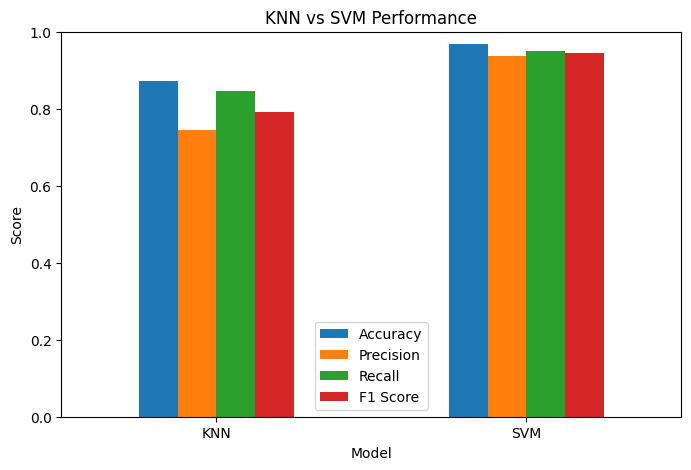

In [11]:
# 8. Compare model performance 
results = pd.DataFrame({ 
    'Model': ['KNN', 'SVM'], 
    'Accuracy': [ 
        accuracy_score(y_test, y_pred_knn), 
        accuracy_score(y_test, y_pred_svm) 
    ], 
    'Precision': [ 
        precision_score(y_test, y_pred_knn, zero_division=0), 
        precision_score(y_test, y_pred_svm, zero_division=0) 
    ], 
    'Recall': [ 
        recall_score(y_test, y_pred_knn, zero_division=0), 
        recall_score(y_test, y_pred_svm, zero_division=0) 
    ], 
    'F1 Score': [ 
        f1_score(y_test, y_pred_knn, zero_division=0), 
        f1_score(y_test, y_pred_svm, zero_division=0) 
    ] 
}) 
print("\nModel Comparison:") 
print(results) 
results.set_index('Model').plot(kind='bar', figsize=(8, 5)) 
plt.title("KNN vs SVM Performance") 
plt.ylabel("Score") 
plt.ylim(0, 1) 
plt.xticks(rotation=0) 
plt.show()

In [13]:
# 9. Conclusion 
if accuracy_score(y_test, y_pred_knn) > accuracy_score(y_test, y_pred_svm): 
    print("KNN performs better in terms of accuracy.") 
elif accuracy_score(y_test, y_pred_svm) > accuracy_score(y_test, y_pred_knn): 
    print("SVM performs better in terms of accuracy.") 
else: 
    print("Both models have equal accuracy.")

SVM performs better in terms of accuracy.
